# Task 3 – Audience Rating Classification

**Goal:** predict the **audience rating category** of a Netflix title from its attributes. This is a *multi-class classification* problem, and a harder one than Task 2: ratings depend on the actual content (violence, language, themes), which we can't see here, so I expect moderate accuracy rather than a perfect one.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Step 0 – Load and clean the data

Before any modelling I load the file and tidy it. What I do, and why:

- **Remove exact duplicate rows** (there are none in this file, but it is a good habit).
- **Parse `date_added`.** In this dataset dates look like `9/25/2021`, so I tell pandas the exact format.
- **Missing values** are not blank here. The file writes `Not Given` for unknown directors and countries, and I keep that in mind (for example `has_director` is 0 when the director is `Not Given`).
- **Turn `duration` into a number.** `"90 min"` becomes 90 and `"2 Seasons"` becomes 2.
- **Simplify genre names.** Netflix names the same genre differently for movies and shows (`Dramas` vs `TV Dramas`, `International Movies` vs `International TV Shows`). I merge them so a genre means the same thing for both types.

In [2]:
DATA_PATH = "Dataset.csv"      # change this if the file is in another folder

df = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)

# Dates (format in this file is month/day/year)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Duration as a number: "90 min" -> 90, "2 Seasons" -> 2
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

# Helpers for comma separated columns
def split_items(text):
    return [p.strip() for p in str(text).split(",") if p.strip()]

def simplify_genre(name):
    """'TV Dramas' and 'Dramas' -> 'Dramas';  'International Movies' -> 'International'."""
    name = name.strip()
    if name in ("Movies", "TV Shows"):
        return "Other"
    name = re.sub(r"^TV\s+", "", name)
    name = re.sub(r"\s+(Movies|TV Shows|TV)$", "", name)
    return name

# Handy columns used by several tasks
df["genre_list"] = df["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
df["n_genres"] = df["genre_list"].apply(len)
df["country_main"] = df["country"].apply(lambda s: split_items(s)[0] if split_items(s) else "Not Given")
df["has_director"] = (df["director"].str.strip() != "Not Given").astype(int)
df["years_to_add"] = (df["year_added"] - df["release_year"]).clip(lower=0)

# 0/1 columns for the 30 most common (simplified) genres, most common first
top_genres = pd.Series([g for lst in df["genre_list"] for g in lst]).value_counts().head(30).index.tolist()
genre_cols = []
for g in top_genres:
    col = "genre_" + g
    df[col] = df["genre_list"].apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

print(df["type"].value_counts().to_dict(), "| date range:", df["date_added"].min().date(), "to", df["date_added"].max().date())
df.head(3)

Dataset shape: (8790, 10)
{'Movie': 6126, 'TV Show': 2664} | date range: 2008-01-01 to 2021-09-25


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,genre_Spanish-Language,genre_Korean,genre_Classic,genre_LGBTQ,genre_Mysteries,genre_Science & Nature,genre_Cult,genre_Anime Features,genre_Other,genre_Teen
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,0,0,0,0,0,0,0,0,0,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,0,0,0,0,0,0,0,0,0,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,0,0,0,0,1,0,0,0,0,0


## Step 1 – Analyze the rating categories

The data has 14 different rating labels, and some are tiny (`NC-17`, `UR`, `TV-Y7-FV`). Classifying that many classes with so few examples would be unreliable, so I group them into four audiences that actually mean something:

| Audience | Ratings |
|---|---|
| **Kids** | TV-Y, TV-Y7, TV-Y7-FV, TV-G, G |
| **Family** | PG, TV-PG |
| **Teens** | PG-13, TV-14 |
| **Adults** | R, TV-MA, NC-17 |

`NR` (not rated) and `UR` (unrated) don't tell us an audience, so I leave them out.

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Rows kept: 8708 of 8790
audience
Adults    4007
Teens     2647
Family    1148
Kids       906
Name: count, dtype: int64


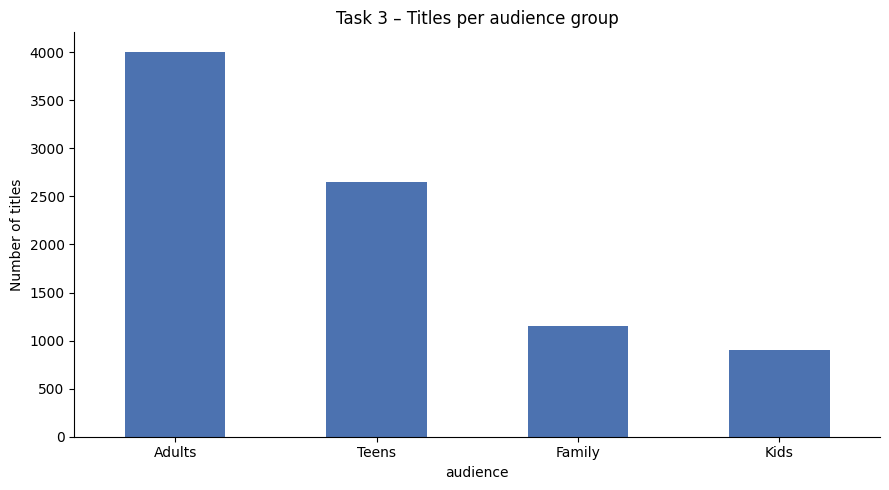

In [3]:
print(df["rating"].value_counts())

audience_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "PG": "Family", "TV-PG": "Family",
    "PG-13": "Teens", "TV-14": "Teens",
    "R": "Adults", "TV-MA": "Adults", "NC-17": "Adults",
}
df["audience"] = df["rating"].map(audience_map)
data = df.dropna(subset=["audience"]).copy()

print(f"\nRows kept: {len(data)} of {len(df)}")
counts = data["audience"].value_counts()
print(counts)

counts.plot(kind="bar", rot=0, color="#4c72b0")
plt.title("Task 3 – Titles per audience group")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

## Step 2 – Prepare training datasets

**Features:** type, release year, duration (as a number), years between release and being added, number of genres, whether a director is listed, main country, and 0/1 columns for the 30 most common genres. Here `duration_num` is fine to use, since the length of a title doesn't reveal its rating the way it revealed its type in Task 2.

The audience groups are unbalanced (Adults is the biggest), so I stratify the split and later use `class_weight="balanced"` so the smaller groups aren't ignored.

In [4]:
numeric_features = (["release_year", "duration_num", "years_to_add", "n_genres", "has_director"] + genre_cols)
categorical_features = ["type", "country_main"]

X = data[numeric_features + categorical_features]
y = data["audience"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categorical_features),
])
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (6966, 37)  Test: (1742, 37)


## Step 3 – Train classification models

First, two reference points:
- A **"always guess the most common class"** dummy model. Any real model must beat this.
- A **Decision Tree** and a **Random Forest** with default-style settings.

In [5]:
def build(clf):
    return Pipeline([("prep", preprocess), ("model", clf)])

baselines = {
    "Majority-class dummy": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
for name, clf in baselines.items():
    pipe = build(clf).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Macro F1": f1_score(y_test, pred, average="macro")})
baseline_results = pd.DataFrame(rows).set_index("Model").round(4)
baseline_results

,Accuracy,Macro F1
Model,,
Majority-class dummy,0.4604,0.1576
Decision Tree,0.5574,0.5348
Random Forest,0.6240,0.5854


## Step 4 – Optimize model performance (hyperparameter tuning)

`GridSearchCV` tries every combination from a small grid, scores each with 3-fold cross-validation on the training data only (so the test set stays untouched), and keeps the best. I score by **macro F1**, which treats every audience group equally instead of rewarding the biggest group.

In [6]:
grids = {
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"model__max_depth": [5, 8, 12, 20],
                       "model__min_samples_leaf": [1, 5, 10, 20]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
                      {"model__n_estimators": [200, 400],
                       "model__max_depth": [10, 20, None],
                       "model__min_samples_leaf": [1, 3, 5]}),
}

tuned, rows = {}, []
for name, (clf, grid) in grids.items():
    search = GridSearchCV(build(clf), grid, cv=3, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
    pred = search.predict(X_test)
    tuned[name] = search
    rows.append({"Model": name + " (tuned)", "Accuracy": accuracy_score(y_test, pred),
                 "Macro F1": f1_score(y_test, pred, average="macro")})
    print(f"{name}: best settings -> {search.best_params_}")

tuned_results = pd.DataFrame(rows).set_index("Model").round(4)
pd.concat([baseline_results, tuned_results])

Decision Tree: best settings -> {'model__max_depth': 20, 'model__min_samples_leaf': 20}
Random Forest: best settings -> {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}


,Accuracy,Macro F1
Model,,
Majority-class dummy,0.4604,0.1576
Decision Tree,0.5574,0.5348
Random Forest,0.6240,0.5854
Decision Tree (tuned),0.5591,0.5540
Random Forest (tuned),0.6286,0.6105


## Step 5 – Evaluate prediction accuracy

Let me look at the best tuned model more closely: a per-class report (which audiences it gets right and wrong), a confusion matrix, and the features it relies on most.

Best model: Random Forest
              precision    recall  f1-score   support

      Adults       0.72      0.72      0.72       802
      Family       0.42      0.47      0.44       230
        Kids       0.78      0.71      0.74       181
       Teens       0.55      0.53      0.54       529

    accuracy                           0.63      1742
   macro avg       0.61      0.61      0.61      1742
weighted avg       0.63      0.63      0.63      1742



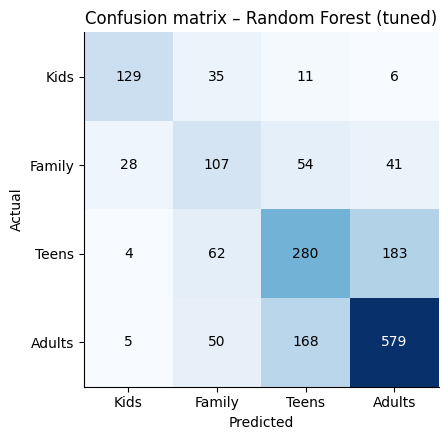

In [7]:
best_name = tuned_results["Macro F1"].idxmax().replace(" (tuned)", "")
best_model = tuned[best_name].best_estimator_
pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, pred))

labels = ["Kids", "Family", "Teens", "Adults"]
cm = confusion_matrix(y_test, pred, labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(labels)
ax.set_yticks(range(4)); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title(f"Confusion matrix – {best_name} (tuned)")
plt.tight_layout()
plt.show()

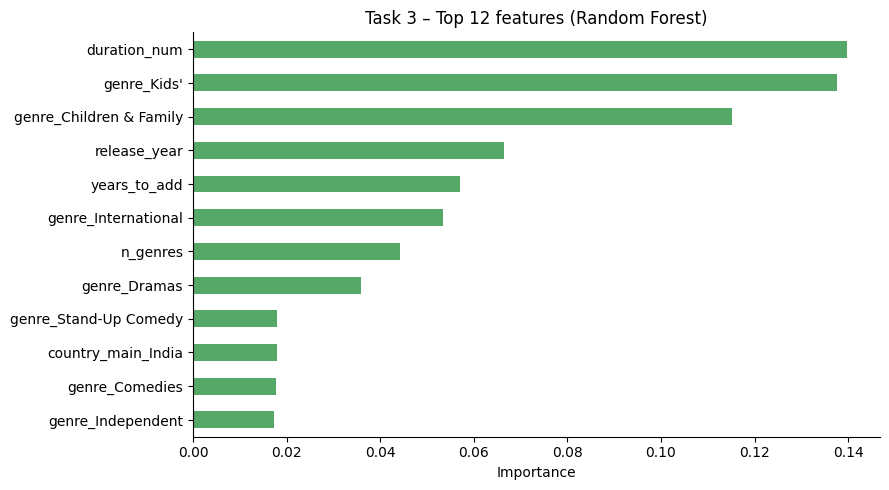

In [8]:
names = [n.replace("num__", "").replace("cat__", "") for n in best_model.named_steps["prep"].get_feature_names_out()]
importance = pd.Series(best_model.named_steps["model"].feature_importances_, index=names)
importance.sort_values().tail(12).plot(kind="barh", color="#55a868")
plt.title(f"Task 3 – Top 12 features ({best_name})")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Conclusion

- Both tuned models clearly beat the "always guess the majority" dummy, so the attributes carry real information about the audience.
- The confusion matrix shows where the mistakes are: neighbouring groups (Teens vs Adults, Family vs Kids) get mixed up the most, which is natural because the real boundaries between ratings are blurry.
- **Limitations:** without plot or content information, there is a ceiling on accuracy. Adding the description text would likely help most.